In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

np.random.seed(2195)

In [41]:
def target_density(x):
    return 0.5 * np.exp(-np.abs(x))

def log_target_density(x):
    return np.log(0.5) - np.abs(x)

def rw_metropolis(N, s, x0):
    x = np.zeros(N + 1)
    x[0] = x0

    for i in range(1, N + 1):
        x_star = np.random.normal(loc=x[i - 1], scale=s)
        log_r = log_target_density(x_star) - log_target_density(x[i - 1])
        log_u = np.log(np.random.uniform(0, 1))

        if log_u < log_r:
            x[i] = x_star
        else:
            x[i] = x[i - 1]

    return x

In [42]:
N_a = 10000
s_a = 1
x0_a = 0

chain_a = rw_metropolis(N=N_a, s=s_a, x0=x0_a)
samples_a_py = chain_a[1:]

mc_mean_py = samples_a_py.mean()
mc_sd_py = samples_a_py.std(ddof=1)

summary_a_py = pd.DataFrame({
    "Statistic": ["Sample mean", "Sample standard deviation"],
    "Value": [mc_mean_py, mc_sd_py]
})

summary_a_py

,Statistic,Value
0,Sample mean,-0.027976
1,Sample standard deviation,1.406689


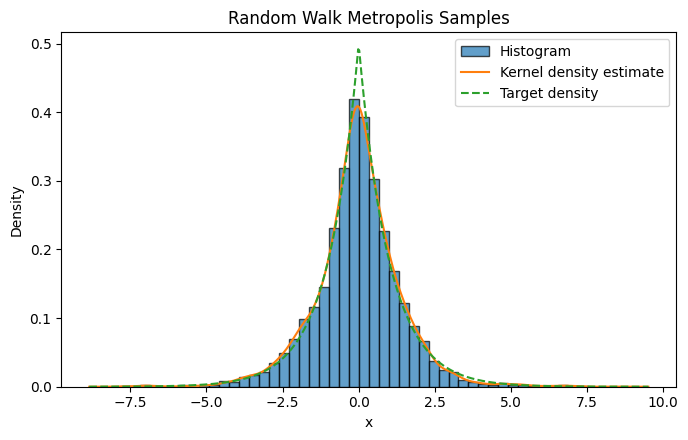

In [43]:
x_grid = np.linspace(samples_a_py.min() - 1, samples_a_py.max() + 1, 500)
kde = gaussian_kde(samples_a_py)

plt.figure(figsize=(7, 4.5))
plt.hist(samples_a_py, bins=50, density=True, alpha=0.7, edgecolor="black", label="Histogram")
plt.plot(x_grid, kde(x_grid), label="Kernel density estimate")
plt.plot(x_grid, target_density(x_grid), linestyle="--", label="Target density")
plt.title("Random Walk Metropolis Samples")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.savefig("part1_python_plot_a.png", dpi=300, bbox_inches="tight")
plt.show()

In [44]:
def compute_rb(chains):
    Mj = chains.mean(axis=1)
    Vj = ((chains - Mj[:, None]) ** 2).mean(axis=1)

    W = Vj.mean()
    M = Mj.mean()
    B = ((Mj - M) ** 2).mean()

    return np.sqrt((B + W) / W)

def generate_chains(N, s, init_vals):
    chains = []

    for x0 in init_vals:
        chain = rw_metropolis(N=N, s=s, x0=x0)[1:]
        chains.append(chain)

    return np.array(chains)

In [45]:
np.random.seed(2195)
N_b = 2000
s_b = 0.001
J_b = 4
x0_b = 0
init_vals = [x0_b] * J_b # chain starting points

chains_b_py = generate_chains(N=N_b, s=s_b, init_vals=init_vals)
rb_0001_py = compute_rb(chains_b_py)

rb_result_py = pd.DataFrame({
    "s": [s_b],
    "J": [J_b],
    "N": [N_b],
    "Rb": [rb_0001_py]
})

rb_result_py

,s,J,N,Rb
0,0.001,4,2000,1.216163


In [46]:
np.random.seed(2195)
s_grid = np.linspace(0.001, 1, 120)

rb_grid_py = np.array([
    compute_rb(generate_chains(N=N_b, s=s_now, init_vals=init_vals))
    for s_now in s_grid
])

rb_plot_df_py = pd.DataFrame({
    "s": s_grid,
    "Rb": rb_grid_py
})

rb_plot_df_py.head()

,s,Rb
0,0.001000,1.216163
1,0.009395,1.220834
2,0.017790,1.194639
3,0.026185,1.698879
4,0.034580,1.514770


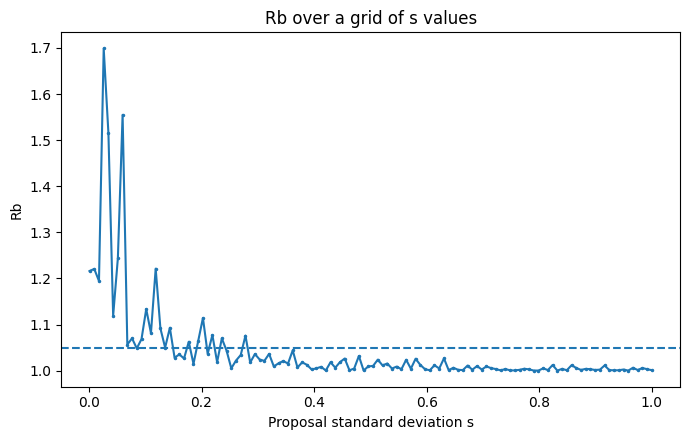

In [47]:
plt.figure(figsize=(7, 4.5))
plt.plot(rb_plot_df_py["s"], rb_plot_df_py["Rb"], marker='.', markersize='3')
plt.axhline(y=1.05, linestyle="--")
plt.title("Rb over a grid of s values")
plt.xlabel("Proposal standard deviation s")
plt.ylabel("Rb")
plt.tight_layout()
plt.savefig("part1_python_plot_b.png", dpi=300, bbox_inches="tight")
plt.show()